In [62]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import glob
import pandas as pd
from sklearn.decomposition import PCA
from pathlib import Path

In [ ]:
# one file
gdf = gpd.read_file("/Users/wm722/Documents/SCDs/results/Inference/Zone36/predictions.shp")
gdf.crs = "EPSG:4326" # change to using wgs84 for consistency across datasets.

In [ ]:
def clean_embeddings(gdf):
    # Extract embeddings (vector representation of object from encoder -> dim squeezed to 32 + scalar features (36 total))
    embed_cols = [f'emb_{i}' for i in range(0, 36)]
    gdf['embeddings'] = gdf[embed_cols].values.tolist()
    
    gdf = gdf.drop(columns=embed_cols)
    gdf = gdf.drop(columns=['embedding'])
    return gdf

def plot_xy_data(gdf, feature_col, ax):
    data = gdf[feature_col]

    # scatter plot of centroids colored by feature value
    gdf['centroid'] = gdf['geometry'].centroid
    ax.scatter(gdf['centroid'].x, gdf['centroid'].y, c=data, cmap='viridis', s=10)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

    # show colorbar
    cbar = plt.colorbar(ax.collections[0], ax=ax)
    cbar.set_label(feature_col)

def fix_overlap(gdfs):
    
    return gdfs

# takes a string of bounds in the format Bounds of DEM: BoundingBox(left=225438.29733716126, bottom=5761037.783712677, right=774528.2973371613, top=6213317.783712677) and returns a tuple of floats
def parse_bounds(bounds_str):

    bounds_str = bounds_str.replace("Bounds of DEM: BoundingBox(", "").replace(")", "")
    bounds_list = bounds_str.split(", ")
    bounds_tuple = tuple(float(b.split("=")[1]) for b in bounds_list)
    print(f"Parsed bounds: {bounds_tuple}")
    return bounds_tuple

In [ ]:
if True:# multiple files
    paths = glob.glob("/Users/wm722/Documents/SCDs/results/Inference/*/*/predictions.shp")
    print(paths)
    gdf_dict= dict()
    for p in paths:
        p = Path(p)
        tmp_gdf = gpd.read_file(p)
        tmp_gdf.crs = "EPSG:4326" # change to using wgs84 for consistency across datasets.

        root = p.parent
        bounds_txt = root / 'covered_bounds.txt'
        if bounds_txt.exists():
            with open(bounds_txt, 'r') as f:
                lines = f.readlines()
                bounds = parse_bounds(lines[1].strip())
        
        gdf_dict[p] = {}
        gdf_dict[p]['covered_bounds'] = bounds
        gdf_dict[p]['gdf'] = tmp_gdf

    gdf_dict = fix_overlap(gdf_dict)
    gdf = gpd.GeoDataFrame(pd.concat(gdf_dict, ignore_index=True), crs=gdf_dict[0].crs)

['/Users/wm722/Documents/SCDs/results/Inference/Zone36/Lats_47_52/predictions.shp', '/Users/wm722/Documents/SCDs/results/Inference/Zone37/Zone37_Lats_47_52/predictions.shp']
Parsed bounds: (225438.29733716126, 5761037.783712677, 774528.2973371613, 6213317.783712677)
Parsed bounds: (225438.2973371626, 5761037.783712677, 774528.2973371625, 6213317.783712677)


/Users/wm722/Tools/miniconda3/envs/scd_env/lib/python3.11/site-packages/pandas/core/generic.py:6448: FutureWarning: Overriding the CRS of a GeoDataFrame that already has CRS. This unsafe behavior will be deprecated in future versions. Use GeoDataFrame.set_crs method instead
  return object.__setattr__(self, name, value)
/Users/wm722/Tools/miniconda3/envs/scd_env/lib/python3.11/site-packages/pandas/core/generic.py:6448: FutureWarning: Overriding the CRS of a GeoDataFrame that already has CRS. This unsafe behavior will be deprecated in future versions. Use GeoDataFrame.set_crs method instead
  return object.__setattr__(self, name, value)


TypeError: fix_overlap() missing 1 required positional argument: 'bounds'

In [50]:
gdf

,object_id,score,area_m2,circ,depth_m,dw_ratio,elongation,eccentrici,geometry,embeddings,centroid,pca1,pca2
0,172,0.824553,23850.0,0.882888,-10.265365,-0.058908,1.347392,0.670207,"POLYGON ((651523.297 6206452.784, 651583.297 6...","[0.224605, 0.0, 0.939762, 0.0, 1.380427, 0.823...",POINT (651544.057 6206360.064),-1.273798,-1.907458
1,502,0.849875,25375.0,0.658020,-3.403442,-0.018935,1.926138,0.854669,"POLYGON ((651473.297 6203787.784, 651493.297 6...","[0.898064, 0.071887, 0.326794, 0.359288, 0.513...",POINT (651492.65 6203640.747),-3.874279,0.391869
2,793,0.846378,25150.0,0.942076,-5.179245,-0.028943,1.119240,0.449136,"POLYGON ((496723.297 6202192.784, 496783.297 6...","[0.840923, 0.0, 0.328454, 0.421187, 0.39093, 0...",POINT (496778.695 6202102.53),-4.218450,0.259613
3,1066,0.833863,24375.0,0.840039,-2.584274,-0.014669,1.102753,0.421514,"POLYGON ((398148.297 6200517.784, 398228.297 6...","[0.0, 0.0, 0.922665, 0.0, 1.453401, 0.489978, ...",POINT (398179.136 6200436.504),-1.232549,1.316872
4,1388,0.979737,40050.0,0.940221,-6.866974,-0.030409,1.052753,0.312584,"POLYGON ((714738.297 6198657.784, 714853.297 6...","[0.630531, 0.0, 0.82053, 0.079915, 1.215786, 1...",POINT (714790.026 6198552.781),-1.829461,-0.348934
...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,46026,0.897908,28950.0,0.942969,-2.345596,-0.012217,1.031485,0.245187,"POLYGON ((526443.297 5774582.784, 526493.297 5...","[0.184691, 0.0, 0.716551, 0.009419, 0.863638, ...",POINT (526459.139 5774482.892),-2.704555,1.466244
467,46122,0.960058,36125.0,0.850897,-12.301270,-0.057358,1.235165,0.586970,"POLYGON ((528013.297 5772317.784, 528068.297 5...","[0.711203, 0.0, 0.695564, 0.182531, 0.896848, ...",POINT (528007.14 5772221.803),-2.503118,-1.998533
468,46197,1.000000,78200.0,0.609634,-7.797699,-0.024712,2.898159,0.938586,"POLYGON ((551428.297 5770732.784, 551483.297 5...","[2.326023, 0.027251, 0.871566, 2.065172, 0.866...",POINT (551600.423 5770596.259),-2.481353,0.809232
469,46376,0.871094,83275.0,0.587190,-1.992645,-0.006120,1.319652,0.652516,"POLYGON ((540718.297 5765942.784, 540773.297 5...","[2.11306, 0.0, 1.783489, 1.913317, 1.87747, 3....",POINT (540703.192 5765751.315),1.101525,2.623437


In [46]:
gdf = clean_embeddings(gdf)

In [ ]:
gdf

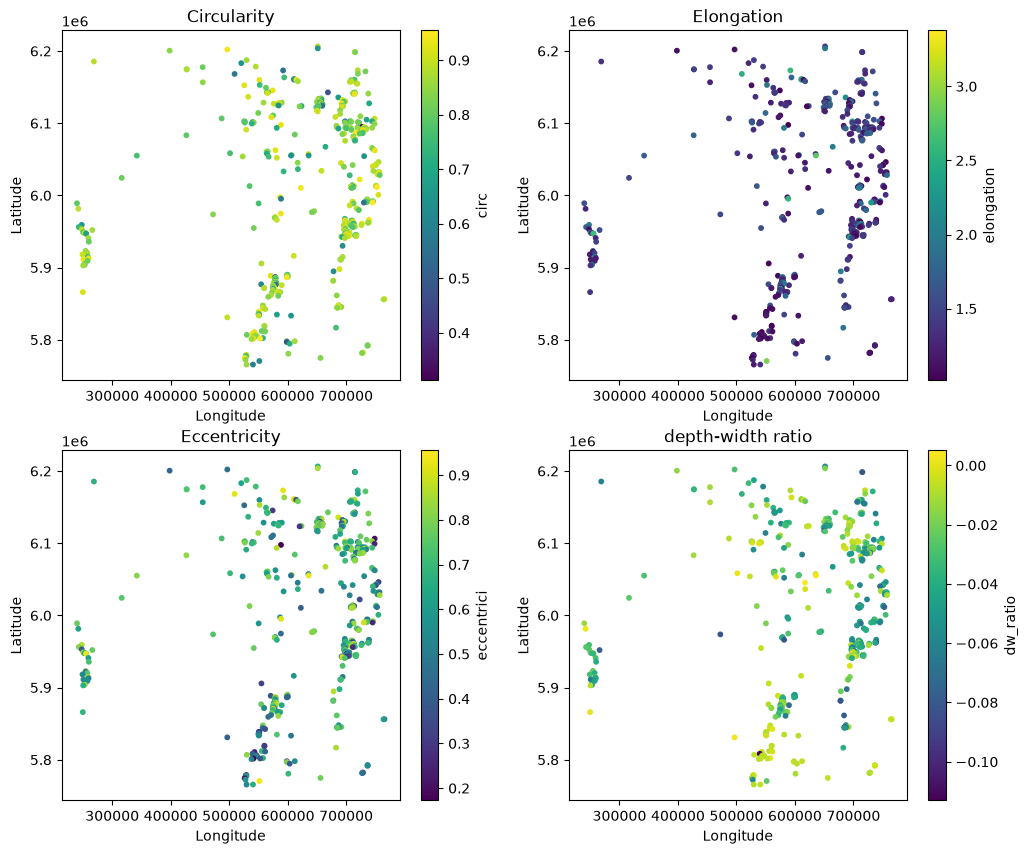

In [47]:
# multipanel figure in (x, y) space showing how circularity, elongation, etc, change spatially. Scatter plot (with centroid, hue by feature value)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].set_title('Circularity')
plot_xy_data(gdf, 'circ', axes[0, 0])
axes[0, 1].set_title('Elongation')
plot_xy_data(gdf, 'elongation', axes[0, 1])
axes[1, 0].set_title('Eccentricity')
plot_xy_data(gdf, 'eccentrici', axes[1, 0])
axes[1, 1].set_title('depth-width ratio')
plot_xy_data(gdf, 'dw_ratio', axes[1, 1])

/var/folders/v2/pgp80k4j40j5r2z4b2mmlr1w0000gp/T/ipykernel_69852/2707057208.py:8: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(pca_result[:, 0], pca_result[:, 1], cmap='viridis', s=10)


Text(0, 0.5, 'PC2 (10.5%)')

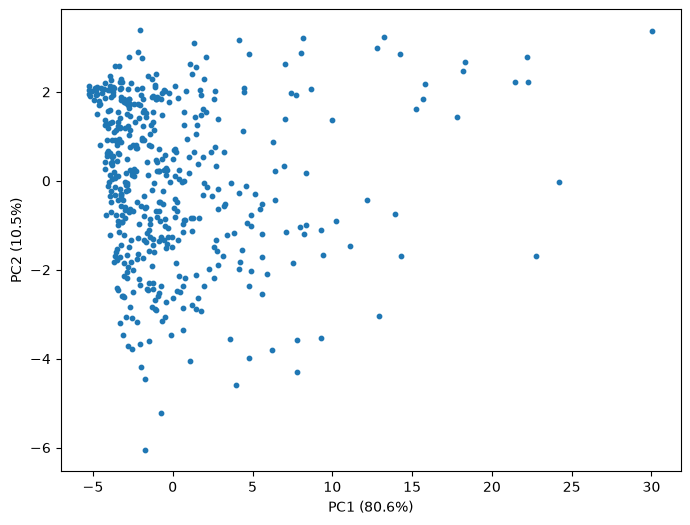

In [48]:
# PCA of embeddings to 2d. plot of pca1 vs pca2.

pca = PCA(n_components=2)
embeddings = np.array(gdf['embeddings'].tolist())
pca_result = pca.fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(pca_result[:, 0], pca_result[:, 1], cmap='viridis', s=10)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})") 


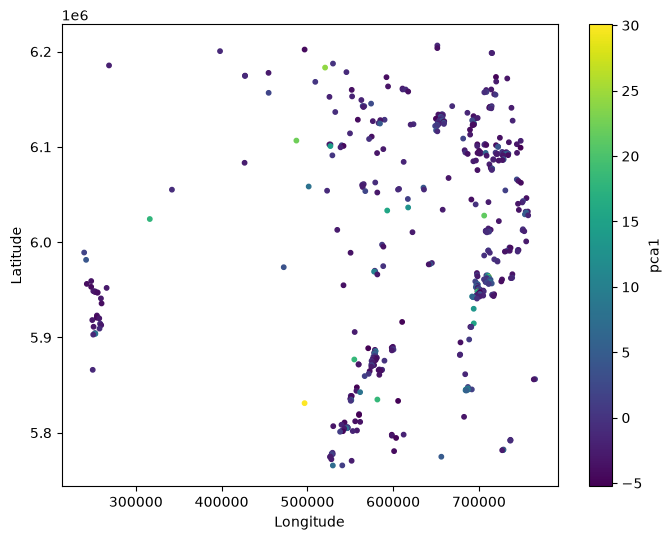

In [49]:
# xy space, hue by pca1
fig, ax = plt.subplots(figsize=(8, 6))
gdf['pca1'] = pca_result[:, 0]
gdf['pca2'] = pca_result[:, 1]
plot_xy_data(gdf, 'pca1', ax)